In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.colors import BoundaryNorm, ListedColormap
import seaborn as sns

from europa_eutectic.gaia_sim import GaiaSim
from europa_eutectic.util import colors


AUX_BASE = Path("../../../../../auxillary")
shell_visc_sims = [json_path for json_path in Path(AUX_BASE / "shell_visc").glob("*.json")]
shell_complex_rheo_sims = [json_path for json_path in Path(AUX_BASE / "shell_complex_rheo").glob("*.json")]
constK_varA_sims = [json_path for json_path in Path(AUX_BASE / "shell_thermal_cond_expan" / "constK_varA").glob("*.json")]
varK_constA_sims= [json_path for json_path in Path(AUX_BASE  / "shell_thermal_cond_expan" / "varK_constA").glob("*.json")]
varK_varA_sims= [json_path for json_path in Path(AUX_BASE    / "shell_thermal_cond_expan" / "varK_varA").glob("*.json")]
shell_tidal_sims = [json_path for json_path in Path(AUX_BASE / "shell_tidal").glob("*.json")]


base_cmap = sns.color_palette("icy_moon_2", as_cmap = True) # My custom colormap

In [2]:
viridis_colors = np.array(sns.color_palette("viridis", 50))

# Slightly brighter than top viridis yellow, but not harsh
viridis_colors[-1] = (0.98, 0.92, 0.28)

custom_cmap = ListedColormap(viridis_colors)

bounds = np.linspace(30, np.nextafter(100.0, 0.0), len(viridis_colors))
bounds = np.append(bounds, np.nextafter(100.0, 101.0))
custom_norm = BoundaryNorm(bounds, ncolors=len(viridis_colors), clip=True)

In [3]:
################################################################################
study_df = pd.read_csv(AUX_BASE / "eutectic_data_full_study.csv")

study_df["log(η_ref) (Pa·s)"] = study_df["log(η_ref) (Pa·s)"].astype(int)
study_df

,Eutectic Type,Eutectic Temperature (K),log(η_ref) (Pa·s),D (km),Eutectic Depth (km),Stagnant Lid Thickness (km),Detectability Low Loss (%),Detectability High Loss (%),Eutectic Amplitude (%),Sim Folder
0,Zolotov,237.15,13,20,6.609407,5.664777,100.0,100.000000,2.609583e+01,shell_visc
1,NaCl,252.05,13,20,7.609907,5.664777,100.0,99.262537,5.869500e+01,shell_visc
2,Zolotov,237.15,14,20,9.830372,8.188686,100.0,100.000000,1.377933e+01,shell_visc
3,NaCl,252.05,14,20,11.591785,8.188686,100.0,91.165414,4.122063e+01,shell_visc
4,Zolotov,237.15,15,20,15.919509,16.824949,100.0,100.000000,6.947938e-07,shell_visc
...,...,...,...,...,...,...,...,...,...,...
85,NaCl,252.05,13,40,7.650664,6.504903,100.0,100.000000,1.184886e+01,shell_tidal
86,Zolotov,237.15,13,50,6.618179,6.658117,100.0,100.000000,3.307494e+00,shell_tidal
87,NaCl,252.05,13,50,7.652806,6.658117,100.0,100.000000,7.932528e+00,shell_tidal
88,Zolotov,237.15,13,60,6.744573,6.663978,100.0,100.000000,4.315958e+00,shell_tidal


In [4]:
detectability_nacl_df = study_df[(study_df["Sim Folder"] == "shell_visc") & (study_df["Eutectic Temperature (K)"] == 252.05)]
detectability_nacl_df = detectability_nacl_df[["D (km)", "log(η_ref) (Pa·s)", "Detectability Low Loss (%)", "Detectability High Loss (%)"]]

detectability_zol_df = study_df[(study_df["Sim Folder"] == "shell_visc") & (study_df["Eutectic Temperature (K)"] == 237.15)]
detectability_zol_df = detectability_zol_df[["D (km)", "log(η_ref) (Pa·s)", "Detectability Low Loss (%)", "Detectability High Loss (%)"]]

detectability_nacl_df

,D (km),log(η_ref) (Pa·s),Detectability Low Loss (%),Detectability High Loss (%)
1,20,13,100.000000,99.262537
3,20,14,100.000000,91.165414
5,20,15,100.000000,100.000000
7,30,13,100.000000,99.599466
9,30,15,100.000000,100.000000
11,40,13,100.000000,99.694423
13,40,15,80.176644,69.087341
15,50,13,99.808429,98.659004
17,40,14,92.895340,92.207792
19,50,14,98.084291,92.145594


In [5]:
zol_low_heatmap_df = detectability_zol_df.pivot(
    index="D (km)",
    columns="log(η_ref) (Pa·s)",
    values="Detectability Low Loss (%)",
)

zol_high_heatmap_df = detectability_zol_df.pivot(
    index="D (km)",
    columns="log(η_ref) (Pa·s)",
    values="Detectability High Loss (%)",
)

nacl_low_heatmap_df = detectability_nacl_df.pivot(
    index="D (km)",
    columns="log(η_ref) (Pa·s)",
    values="Detectability Low Loss (%)",
)


nacl_high_heatmap_df = detectability_nacl_df.pivot(
    index="D (km)",
    columns="log(η_ref) (Pa·s)",
    values="Detectability High Loss (%)",
)


In [6]:
nacl_low_heatmap_df

log(η_ref) (Pa·s),12,13,14,15
D (km),,,,
20,100.0,100.000000,100.000000,100.000000
30,100.0,100.000000,91.873964,100.000000
40,100.0,100.000000,92.895340,80.176644
50,100.0,99.808429,98.084291,80.651341
60,100.0,99.654378,99.308756,77.649770


In [7]:
nacl_high_heatmap_df

log(η_ref) (Pa·s),12,13,14,15
D (km),,,,
20,100.0,99.262537,91.165414,100.000000
30,100.0,99.599466,90.878939,100.000000
40,100.0,99.694423,92.207792,69.087341
50,100.0,98.659004,92.145594,60.057471
60,100.0,98.502304,86.290323,34.101382


/var/folders/21/1lgl4bt141nf87j2l6lc_nw00000gn/T/ipykernel_18433/879725216.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.03, 0.9, 1])


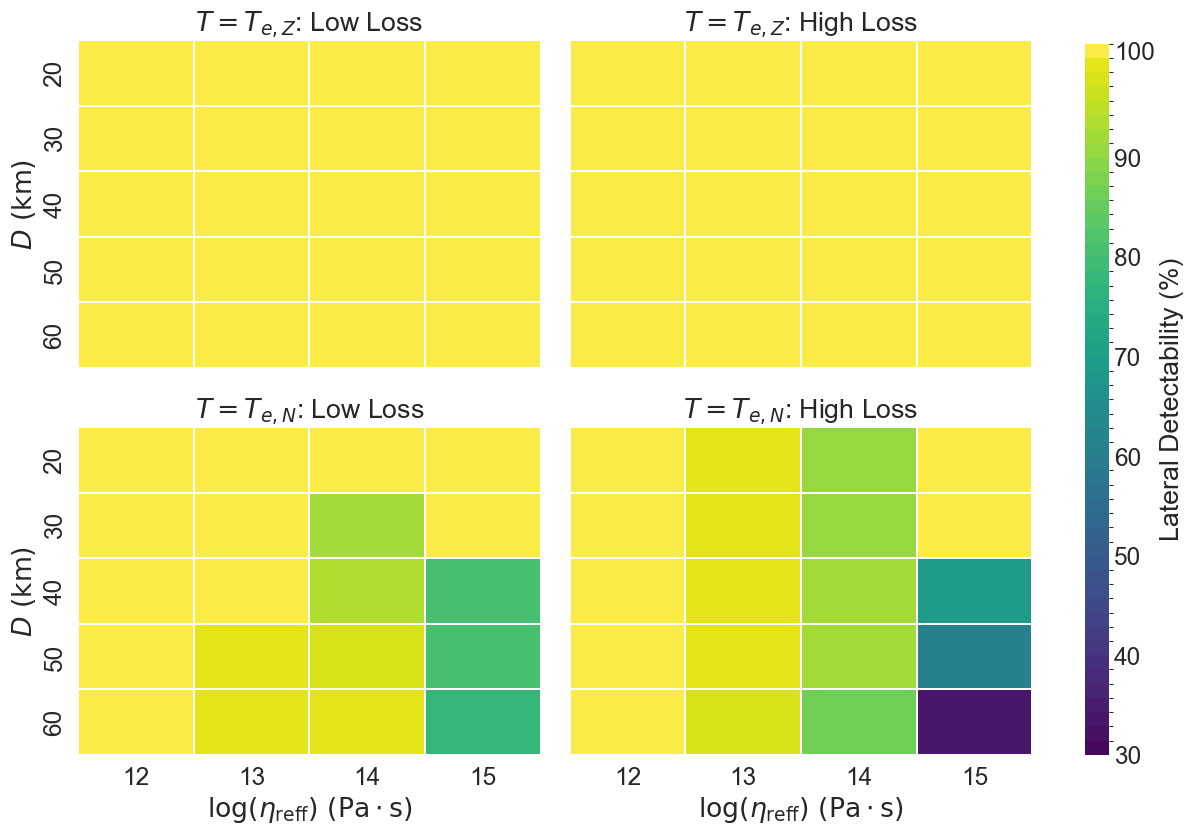

In [8]:
sns.set_theme(style="whitegrid", context="paper", font_scale=2)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
cbar_ax = fig.add_axes([0.92, 0.14, 0.02, 0.79])

heatmap_kwargs = dict(
    cmap=custom_cmap,
    norm = custom_norm,
    cbar=False,
    linewidths=0.3,
)

sns.heatmap(zol_low_heatmap_df, ax=axes[0, 0], **heatmap_kwargs)
sns.heatmap(zol_high_heatmap_df, ax=axes[0, 1], **heatmap_kwargs)
sns.heatmap(nacl_low_heatmap_df, ax=axes[1, 0], **heatmap_kwargs)
sns.heatmap(
    nacl_high_heatmap_df,
    ax=axes[1, 1],
    cmap=custom_cmap,
    norm=custom_norm,
    cbar=True, 
    cbar_ax=cbar_ax,
    cbar_kws={"label": "Lateral Detectability (%)", "ticks": [30, 40, 50, 60, 70, 80, 90, 100]},
    linewidth = 0.3,
)
cbar_ax.tick_params(length=0)

Zolotov = r"$T = T_{e,Z}$"
NaCl = r"$T = T_{e,N}$"

axes[0, 0].set_title(f"{Zolotov}: Low Loss")
axes[0, 1].set_title(f"{Zolotov}: High Loss")
axes[1, 0].set_title(f"{NaCl}: Low Loss")
axes[1, 1].set_title(f"{NaCl}: High Loss")

for idx, ax in enumerate(axes.flat):
    ax.set_xlabel("")
    ax.set_ylabel("")
    if idx in [2, 3]:
        ax.set_xlabel(r"$\log(\eta_{\mathrm{reff}})\ \mathrm{(Pa\cdot s)}$")
    if idx in [0, 2]:
        ax.set_ylabel(r"$D\ \mathrm{(km)}$")    

fig.tight_layout(rect=[0, 0.03, 0.9, 1])
fig.savefig("../images/figure5.png", transparent=True, dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()

In [9]:
################################################################################
detectability_complex_df = study_df[(study_df["Sim Folder"] != "shell_visc")]
detectability_zol_df = detectability_complex_df[detectability_complex_df["Eutectic Temperature (K)"] == 237.15]
detectability_nacl_df = detectability_complex_df[detectability_complex_df["Eutectic Temperature (K)"] == 252.05]

detectability_zol_complex_df = detectability_complex_df[["D (km)", "log(η_ref) (Pa·s)", "Detectability Low Loss (%)", "Detectability High Loss (%)", "Sim Folder"]]
detectability_nacl_complex_df = detectability_complex_df[["D (km)", "log(η_ref) (Pa·s)", "Detectability Low Loss (%)", "Detectability High Loss (%)", "Sim Folder"]]
detectability_zol_complex_df

,D (km),log(η_ref) (Pa·s),Detectability Low Loss (%),Detectability High Loss (%),Sim Folder
40,30,13,100.000000,100.000000,constK_varA
41,30,13,100.000000,99.799733,constK_varA
42,40,13,100.000000,100.000000,constK_varA
43,40,13,100.000000,99.770817,constK_varA
44,50,13,100.000000,100.000000,constK_varA
45,50,13,100.000000,99.808429,constK_varA
46,20,13,100.000000,100.000000,constK_varA
47,20,13,100.000000,100.000000,constK_varA
48,60,13,100.000000,100.000000,constK_varA
49,60,13,99.769585,98.732719,constK_varA


In [10]:
################################################################################

sim_folder_order = [
    "constK_varA",
    "varK_constA",
    "varK_varA",
    "shell_complex_rheo",
    "shell_tidal"
]

detectability_zol_df["Sim Folder"] = pd.Categorical(
    detectability_zol_df["Sim Folder"],
    categories=sim_folder_order,
    ordered=True,
)

detectability_nacl_df["Sim Folder"] = pd.Categorical(
    detectability_nacl_df["Sim Folder"],
    categories=sim_folder_order,
    ordered=True,
)


complex_zol_low_heatmap_df = detectability_zol_df.pivot(
    index="D (km)",
    columns="Sim Folder",
    values="Detectability Low Loss (%)",
)

complex_zol_high_heatmap_df = detectability_zol_df.pivot(
    index="D (km)",
    columns="Sim Folder",
    values="Detectability High Loss (%)",
)

complex_nacl_low_heatmap_df = detectability_nacl_df.pivot(
    index="D (km)",
    columns="Sim Folder",
    values="Detectability Low Loss (%)",
)

complex_nacl_high_heatmap_df = detectability_nacl_df.pivot(
    index="D (km)",
    columns="Sim Folder",
    values="Detectability High Loss (%)",
)

complex_nacl_high_heatmap_df

/var/folders/21/1lgl4bt141nf87j2l6lc_nw00000gn/T/ipykernel_18433/1655855425.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  detectability_zol_df["Sim Folder"] = pd.Categorical(
/var/folders/21/1lgl4bt141nf87j2l6lc_nw00000gn/T/ipykernel_18433/1655855425.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  detectability_nacl_df["Sim Folder"] = pd.Categorical(


Sim Folder,constK_varA,varK_constA,varK_varA,shell_complex_rheo,shell_tidal
D (km),,,,,
20,100.000000,89.601770,92.182891,98.040693,100.000000
30,99.799733,98.664887,99.465955,99.592391,100.000000
40,99.770817,98.242934,99.312452,99.770817,100.000000
50,99.808429,95.306513,96.455939,98.563218,100.000000
60,98.732719,91.820276,89.516129,99.078341,99.539171


/var/folders/21/1lgl4bt141nf87j2l6lc_nw00000gn/T/ipykernel_18433/2262656804.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.03, 0.9, 1])


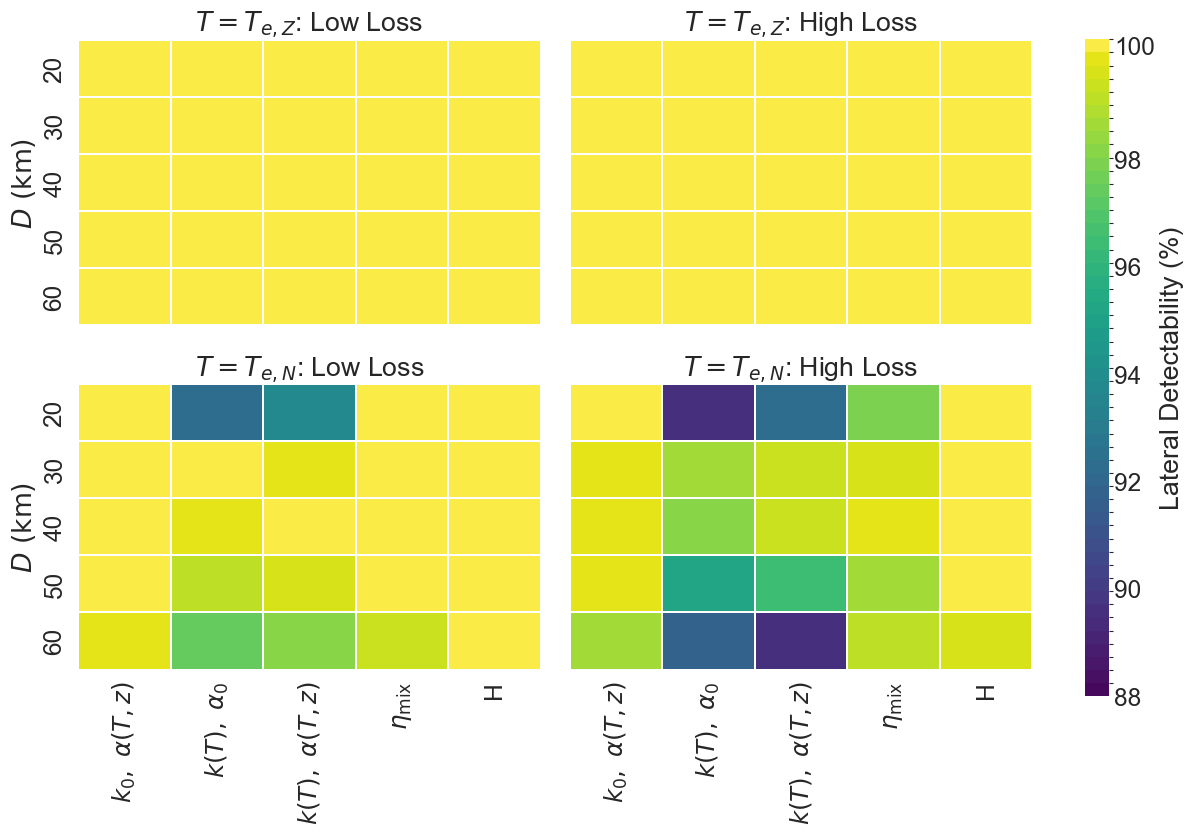

In [11]:
################################################################################
bounds = np.linspace(88, np.nextafter(100.0, 0.0), len(viridis_colors))
bounds = np.append(bounds, np.nextafter(100.0, 101.0))
custom_norm = BoundaryNorm(bounds, ncolors=len(viridis_colors), clip=True)


sns.set_theme(style="whitegrid", context="paper", font_scale=2)

sim_folder_map = {
    "constK_varA": r"$k_0,\ \alpha(T, z)$",
    "varK_constA": r"$k(T),\ \alpha_0$",
    "varK_varA": r"$k(T),\ \alpha(T, z)$",
    "shell_complex_rheo": r"$\eta_{\mathrm{mix}}$",
    "shell_tidal": r"H"
}
for df in [complex_zol_low_heatmap_df, complex_zol_high_heatmap_df, complex_nacl_low_heatmap_df, complex_nacl_high_heatmap_df]:
    df.rename(columns=sim_folder_map, inplace=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
cbar_ax = fig.add_axes([0.92, 0.205, 0.02, 0.73])

heatmap_kwargs = dict(
    cmap=custom_cmap,
    norm=custom_norm,
    cbar=False,
    linewidths=0.3,
)

sns.heatmap(complex_zol_low_heatmap_df, ax=axes[0, 0], **heatmap_kwargs)
sns.heatmap(complex_zol_high_heatmap_df, ax=axes[0, 1], **heatmap_kwargs)
sns.heatmap(complex_nacl_low_heatmap_df, ax=axes[1, 0], **heatmap_kwargs)
sns.heatmap(
    complex_nacl_high_heatmap_df,
    ax=axes[1, 1],
    cmap=custom_cmap,
    norm=custom_norm,
    cbar=True,
    cbar_ax=cbar_ax,
    cbar_kws={"label": "Lateral Detectability (%)", "ticks": [88, 90, 92, 94, 96, 98, 100]},
    linewidths=0.3,
 )
cbar_ax.tick_params(length=0)

Zolotov = r"$T = T_{e,Z}$"
NaCl = r"$T = T_{e,N}$"

axes[0, 0].set_title(f"{Zolotov}: Low Loss")
axes[0, 1].set_title(f"{Zolotov}: High Loss")
axes[1, 0].set_title(f"{NaCl}: Low Loss")
axes[1, 1].set_title(f"{NaCl}: High Loss")

for idx, ax in enumerate(axes.flat):
    ax.set_xlabel("")
    ax.set_ylabel("")
    if idx in [0, 2]:
        ax.set_ylabel(r"$D\ \mathrm{(km)}$")

fig.tight_layout(rect=[0, 0.03, 0.9, 1])
fig.savefig("../images/figure6.png", transparent=True, dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()